In [71]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/26/2022
# version ='1.0'

\section{Demo: Further Experiments on Solving a Small SDP by Barrier Method}

In book-convex-2004, the barrier method was used to solve the following SDP problem:
\begin{equation}
\begin{array}{rl}
\text{minimize} & c^Tx \\
\text{subject to} & F(x)=\displaystyle{\sum_{i=1}^{n}}x_iF_i+G \preceq 0 \\
\end{array}
\end{equation}
where $x\in R^n$, and $F_i\in S^p, G\in S^p$. This demo will explain in more details how to run experiments to solve the above SDP problem.

The dual problem is (refer to example 11.9 in the textbook),

\begin{equation}
\begin{array}{rll}
\text{maximize} & tr(GZ) & \\
\text{subject to} & tr(F_iZ)+c_i = 0 & i=1,2,..,n \\
& Z \succeq 0 & \\
\end{array}
\end{equation}

The optimality conditions for the above SDP problem is, $\exists x^*, Z^*$ to satisfy
\begin{equation}
\begin{array}{cccc}
c + \left[\begin{array}{c}
\vdots \\
tr(Z^*F_i) \\
\vdots \\
\end{array} \right] = 0, & F(x^*)\preceq 0, & Z^* \succeq 0, & tr(Z^*F(x^*))=0 \\
\end{array}
\end{equation}
It requires either $Z^*=0$ or $F(x^*)=0$. However, if $Z^*=0$, then $c=0$, the problem becomes trivial. In the experiment, it is assumed that $F(x^*)=0$.

The problem parameters, $c, F, G$ are generated in the following procedure, so that the problem is strictly primal and dual feasible and having the optimal value, $p^*=1$. 


### Procedure to generate parameters $(c, F, G, x^*, Z^*, p^*=1)$ and initial starting point $x_0$}

1. Randomly generate $x^*\in \mathbf{N}(0, 1)^n$ (i.e., normal distribution)
1. For $i=1,...,n-1$, randomly generate $F_i\in S^p$
1. Randomly generate $\Delta_x \in \mathbf{N}(0,1)^n$, and a negative matrix $R\in S_-^p$
1. Determine $F_{n}$ by satisfying $\Delta_{x,1}F_1+\Delta_{x,2}F_2+...+\Delta_{x,n}F_n=R$
1. Determine $G$ by satisfying $F(x^*)=x^*_1F_1+x^*_2F_2+...+x^*_nF_n+G=0$. In this way, for any $Z$, $tr(ZF(x^*))=0$.
1. Determine $x_0\leftarrow x^*+\Delta_x$. In this way, $F(x_0)=F(x^*)+R\prec 0$, so $x_0$ is a strictly feasible point.
1. Randomly generated $Z^*\in S^p_{+}$ satisfying $tr(Z^*G)>0$ and then scale $Z^*$ to satisfy $tr(Z^*G)=p^*$

Note that it may require repeating the above steps in generating $G$ and $Z^*$ several times until they can satisfy $tr(Z^*G)>0$

8. Determine $c$ by satisfying 
$$
\begin{array}{c}
c + \left[\begin{array}{c}
\vdots \\
tr(Z^*F_i) \\
\vdots \\
\end{array} \right] = 0 \\
\end{array}
$$


In the barrier method, the logarithmic barrier function $\phi(x)=-\log det \left(-F(x)\right)$. Its gradient is
\begin{equation}
\begin{array}{rcl}
\nabla\phi(x) & = & \left[\begin{array}{c}
\vdots \\
tr(-F(x)^{-1}F_i) \\
\vdots \\
\end{array} \right]
\end{array}
\end{equation}
Its hessian, $\nabla^2\phi(x)$, is calculated by utilizing the following approximation
$$
(Y+\Delta Y)^{-1} \approx Y^{-1}-Y^{-1}\Delta Y Y^{-1} 
$$
Then, 
$$
\begin{array}{rcl}
-F(x+\Delta x_j \vec{e}_j)^{-1} & = & \left[-F(x)-\Delta x_jF_j \right]^{-1} \\
& \approx & -F(x)^{-1} - (-F(x))^{-1}(-\Delta x_jF_j)(-F(x))^{-1} \\
\end{array}
$$
And,
$$
\begin{array}{rcl}
tr(-F(x+\Delta x_j \vec{e}_j)^{-1}F_i) & \approx & tr(-F(x)^{-1}F_i)+(\Delta x_j) tr((-F(x)^{-1})F_j(-F(x)^{-1})F_i)\\
\end{array}
$$
As a result,
$$
\begin{array}{rcl}
\nabla^2\phi(x)_{i,j} & = & \displaystyle{\lim_{\Delta x_j\rightarrow 0}}\dfrac{tr(-F(x+\Delta x_j \vec{e}_j)^{-1}F_i) - tr(-F(x)^{-1}F_i)}{\Delta x_j} \\
& = & tr((-F(x)^{-1})F_j(-F(x)^{-1})F_i) \\
\end{array}
$$

Another risk in the implementation of the barrier method is the numerical calculation of $\phi(x)=-\log det \left(-F(x)\right)$. 

In python when $n$ is up to 100, and 200, $det(-F(x))$ may be as high as to $10^{300}$ or as low as to $10^{-300}$, which is an overflow in python. When overlfow occurs in python, $\phi(x)$ will become $inf$, and the Newton iterations will not be converged. 

One method to alleviate this risk is, if $\phi(x)$ is $inf$, then $-F(x)$ is first scaled by $\beta$ (e.g., $\beta=2^k$ or $\beta=0.5^k$) and then $\phi(x)$ is recalculated again.

In [72]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

In [73]:
def is_pos_def(x):
    """
    utility function, check whether matrix x is positive definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) > 0)


def is_neg_def(x):
    """
    utility function, check whether matrix x is negative definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) < 0)


def is_semi_pos_def(x):
    """
    utility function, check whether matrix x is semi-positive definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) >= 0)


def is_semi_neg_def(x):
    """
    utility function, check whether matrix x is semi-negative definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) <= 0)

$f_0(x)=c^Tx$

$\nabla f_0(x)=c$

$\nabla^2 f_0(x)=0$

In [74]:
def my_f_0(x, c, F, G):
    """
    $f_0(x)=c^Tx$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return (c.T @ x).item()


def my_f_0_feasible(x, c, F, G):
    return True


def my_gradient_f_0(x, c, F, G):
    """
    $\nabla f_0(x)=c$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return c


def my_hessian_f_0(x, c, F, G):
    """
    $\nabla^2 f_0(x)=0$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return np.zeros((len(x), len(x)))

$\phi(x)=-\log det(-F(x))$

It requires $F(x)\succ 0$

The gradient of $\phi(x)$
    \begin{equation}
    \begin{array}{rcl}
    \nabla\phi(x) & = & \left[\begin{array}{c}
    \vdots \\
    tr(-F(x)^{-1}F_i) \\
    \vdots \\
    \end{array} \right]
    \end{array}
    \end{equation}
    
The hessian of $\phi(x)$
    $$
    \begin{array}{rcl}
    \nabla^2\phi(x)_{i,j} & = & \displaystyle{\lim_{\Delta x_j\rightarrow 0}}\dfrac{tr(-F(x+\Delta x_j \vec{e}_j)^{-1}F_i) - tr(-F(x)^{-1}F_i)}{\Delta x_j} \\
    & = & tr((-F(x)^{-1})F_j(-F(x)^{-1})F_i) \\
    \end{array}
    $$

In [75]:
def my_phi(x, c, F, G):
    """
    $\phi(x)=-\log det(-F(x))$
    If overflow occurs in calculating $det(-F(x))$,
    then $F(x)$ will be scaled up by 2 or down by 0.5 recursively,
    until no overflow occurs.
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]
    # print('Debug: trace(-Fx)={}'.format(np.trace(-Fx)))

    with warnings.catch_warnings():
        warnings.filterwarnings('ignore')
        phi = -1 * np.log(np.linalg.det(-Fx))
        if phi < 0 and np.isinf(phi):
            scale = 0.5
            while scale >= 2 ** -30:
                scaled_Fx = scale * Fx
                phi = -1 * (np.log(np.linalg.det(-scaled_Fx)) - n * np.log(scale))
                if not np.isinf(phi):
                    break
                scale *= 1 / 2
            if np.isinf(phi):
                raise RuntimeError('phi = -inf')
            return phi
        elif phi > 0 and np.isinf(phi):
            scale = 2
            while scale <= 2 ** 30:
                scaled_Fx = scale * Fx
                phi = -1 * (np.log(np.linalg.det(-scaled_Fx)) - n * np.log(scale))
                if not np.isinf(phi):
                    break
                scale *= 2
            if np.isinf(phi):
                raise RuntimeError('phi = +inf')
            return phi
        else:
            return phi


def my_phi_feasible(x, c, F, G):
    """
    It requires $F(x)\succ 0 $
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]
    return is_semi_neg_def(Fx)


def my_gradient_phi(x, c, F, G):
    """
    gradient of $\phi(x)$
    \begin{equation}
    \begin{array}{rcl}
    \nabla\phi(x) & = & \left[\begin{array}{c}
    \vdots \\
    tr(-F(x)^{-1}F_i) \\
    \vdots \\
    \end{array} \right]
    \end{array}
    \end{equation}
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]
    g = [np.trace(-1 * np.linalg.inv(Fx) @ F[i]) for i in range(n)]
    return np.reshape(np.array(g), (n, 1))


def my_hessian_phi(x, c, F, G):
    """
    Hessian of $\phi(x)$
    $$
    \begin{array}{rcl}
    \nabla^2\phi(x)_{i,j} & = & \displaystyle{\lim_{\Delta x_j\rightarrow 0}}\dfrac{tr(-F(x+\Delta x_j \vec{e}_j)^{-1}F_i) - tr(-F(x)^{-1}F_i)}{\Delta x_j} \\
    & = & tr((-F(x)^{-1})F_j(-F(x)^{-1})F_i) \\
    \end{array}
    $$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]

    minus_inv_Fx = -1 * np.linalg.inv(Fx)
    H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            H[i][j] = np.trace(minus_inv_Fx @ F[j] @ minus_inv_Fx @ F[i])

    if not is_pos_def(H):
        raise RuntimeError('Hessian should be positive.')
    return H

$f(x)=tf_0(x)+\phi(x)$

$\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$

$\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$



In [76]:
def my_f(x, t, c, F, G):
    """
    $f(x)=tf_0(x)+\phi(x)$
    :param x:
    :param t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return t * my_f_0(x, c, F, G) + my_phi(x, c, F, G)


def my_f_feasible(x, t, c, F, G):
    return my_f_0_feasible(x, c, F, G) and my_phi_feasible(x, c, F, G)


def my_gradient_f(x, t, c, F, G):
    """
    $\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$
    :param x:
    :param t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return t * my_gradient_f_0(x, c, F, G) + my_gradient_phi(x, c, F, G)


def my_hessian_f(x, t, c, F, G):
    """
    $\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$
    :param x:
    :param t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return t * my_hessian_f_0(x, c, F, G) + my_hessian_phi(x, c, F, G)

Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$

In [77]:
def my_newton_step_decrement(x, args):
    """
    Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    :param x:
    :param args:
    :return:
    """
    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    KKT = hessian
    residual = gradient
    cond = np.linalg.cond(KKT)
    if cond < 1e30:
        x_nt = np.linalg.inv(KKT) @ (-1 * residual)
        decrement_1 = -1 * gradient.T @ x_nt
        decrement_2 = x_nt.T @ hessian @ x_nt
        if not np.allclose(decrement_1, decrement_2):
            print('Warning: Quantization error detected in the two ways in calculating the decrement')
        if decrement_1 < 0:
            print('Warning: Quantization error detected as the Newton step x_{nt} is not in the descent direction')

        decrement = decrement_2
        return x_nt, decrement.item()
    else:
        raise RuntimeError('the KKT system is not invertible!')

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [78]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    s = 1
    while (not my_f_feasible(x + delta_x * s, *args)) \
            or f(x + delta_x * s, *args) > f(x, *args) + alpha * s * ((df(x, *args).T @ delta_x).item()):
        s = beta * s
    return s

The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.

In [79]:
def centering_step(x0, epsilon, alpha, beta, barrier_t, c, F, G):
    """
    The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.
    :param x0:
    :param epsilon:
    :param alpha:
    :param beta:
    :param barrier_t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    x = x0
    args = (barrier_t, c, F, G)
    x_nt, decrement = my_newton_step_decrement(x, args)

    line_search_steps = []
    fx = [my_f(x, *args)]
    decrements = [decrement]
    iteration = 1
    while decrement / 2 > epsilon:
        step = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
        x_next = x + step * x_nt
        x = x_next
        x_nt, decrement = my_newton_step_decrement(x, args)

        #print(r'Info: iteration={}, barrier_t={}, decrement={}, line search step ={}'.format(iteration, barrier_t,
        #                                                                                     decrement, step))
        line_search_steps.append(step)
        fx.append(my_f(x, *args))
        decrements.append(decrement)

        iteration = iteration + 1

    n_iter = iteration
    xt = x
    return xt, n_iter, fx, decrements, line_search_steps

Procedure to generate parameters $(c, F, G, x^*, Z^*, p^*=1)$ and initial starting point $x_0$

Refer to FlexibleLecture Note for details

In [80]:
def get_c_F_G_xp_Z(n, p, p_asterisk):
    """
    Procedure to generate parameters $(c, F, G, x^*, Z^*, p^*=1)$ and initial starting point $x_0$
    Refer to FlexibleLecture Note for details
    :param n:
    :param p:
    :param p_asterisk:
    :return:
    """
    if not p_asterisk > 0:
        raise RuntimeError('Only fp > 0 is supported yet.')

    dial = 0
    while True:
        x_asterisk = np.random.uniform(low=-1.0, high=1.0, size=(n, 1))
        dx = np.random.uniform(low=-1.0, high=1.0, size=(n, 1))
        assert (not np.allclose(dx[n - 1][0], 0))
        F = np.zeros((n, p, p))
        Tmp = np.random.rand(p, p)
        R = -1 * (Tmp @ Tmp.T)  # -R is SDP

        for i in range(n - 1):
            Tmp = np.random.normal(loc=0, scale=1.0, size=(p, p))
            F[i] = (Tmp + Tmp.T) / 2  # $F_i$ is symmetric

        Tmp = np.zeros((p, p))
        for i in range(n - 1):
            Tmp += dx[i][0] * F[i]

        F[n - 1] = (R - Tmp) / dx[n - 1][0]

        Tmp = np.zeros((p, p))
        for i in range(n):
            Tmp += dx[i][0] * F[i]
        if not is_neg_def(Tmp):
            raise RuntimeError('F(dx)-G should be negative definite!')

        G = np.zeros((p, p))
        for i in range(n):
            G += -x_asterisk[i][0] * F[i]

        Tmp = np.random.rand(p, p)
        Z_tmp = Tmp @ Tmp.T
        scale = p_asterisk / np.trace(Z_tmp @ G)
        if scale > 0:
            Z = Z_tmp * scale
            #print('Info: model parameters are successfully constructed.')
            break
        else:
            dial += 1
            #print('Info: The {}-th dial to generate Z failed, continue to the next dial'.format(dial))
            continue

    if not np.allclose(np.trace(Z @ G), p_asterisk):
        raise RuntimeError('it is requiring the optimal value is fp.')

    Tmp = G.copy()
    for i in range(n):
        Tmp += x_asterisk[i][0] * F[i]

    if not np.allclose(Tmp, np.zeros((p, p))):
        raise RuntimeError('it should satisfy the optimal condition, F(xp)=0')

    x0 = x_asterisk + dx

    Tmp = G.copy()
    for i in range(n):
        Tmp += x0[i][0] * F[i]
    if not is_neg_def(Tmp):
        raise RuntimeError('it should have F(x0)<0')

    c = np.zeros((n, 1))
    for i in range(n):
        c[i][0] = -np.trace(Z @ F[i])

    return c, F, G, Z, x_asterisk, x0

plot the figure showing duality gap, Newton decrement, Newton step length,
    $f_0-f_p (f_p=p^*)$  versus cumulative number of Newton steps

In [81]:
def plot_figure_convergence(n, p, p_asterisk, mu_s, seed):
    """
    plot the figure showing duality gap, Newton decrement, Newton step length,
    $f_0-f_p (f_p=p^*)$  versus cumulative number of Newton steps
    :param n:
    :param p:
    :param p_asterisk:
    :param mu_s:
    :param seed:
    :return:
    """
    plt.figure(figsize=(12, 9))
    ax1 = plt.subplot(3, 1, 1)
    ax1_twin = ax1.twinx()

    ax2 = plt.subplot(3, 1, 2)
    ax2_twin = ax2.twinx()

    ax3 = plt.subplot(3, 1, 3)
    ax3_twin = ax3.twinx()

    colors = ['black', 'purple', 'orange', 'magenta']
    markers = ['o', 's', 'v', '<']

    np.random.seed(seed)

    c, F, G, Z, x_asterisk, x0 = get_c_F_G_xp_Z(n, p, p_asterisk)

    Fx = G.copy()
    for i in range(n):
        Fx += x_asterisk[i][0] * F[i]
    if not is_semi_neg_def(Fx):
        if not np.allclose(np.linalg.eigvals(Fx), np.zeros((p,))):
            raise RuntimeError('it should be Fx <= 0')
    if not np.allclose(np.trace(Z @ Fx), 0):
        raise RuntimeError('tr(Z @ Fx)=0')
    if not is_semi_pos_def(Z):
        raise RuntimeError('it should be Z >= 0')
    g = np.reshape(np.array([np.trace(Z @ F[i]) for i in range(n)]), (n, 1))
    if not np.allclose(-c, g):
        raise RuntimeError('it should be c+g=0')

    alpha = 0.01
    beta = 0.5
    epsilon = 1e-5
    duality_gap_epsilon = 1 * 1e-4

    for mu_i, mu in enumerate(mu_s):
        color = colors[mu_i]
        marker = markers[mu_i]

        t0 = 1
        t = t0

        # To ensure that the initial point is on the central path with t_0 = 1
        #print('Info: running the centering step once to ensure that the initial point is on the central path with t_0=1')
        args = (t, c, F, G)
        xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)
        x0 = xt
        t = mu * t

        cumulative_iteration = 0
        dual_gaps = []
        decrements = []
        iteration_index_vs_decrement = []
        line_search_steps = []
        f0 = []

        #print("Info: start the barrier method and its iterations ...")
        while True:
            args = (t, c, F, G)
            xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)

            f0 = f0 + [my_f_0(x0, c, F, G)] * len(decrement)
            line_search_steps = line_search_steps + tx
            dual_gaps = dual_gaps + [p / (t / mu)] * len(decrement)
            decrements = decrements + decrement
            iteration_index_vs_decrement = iteration_index_vs_decrement + [i for i in range(cumulative_iteration, cumulative_iteration + n_iter)]
            cumulative_iteration = cumulative_iteration + n_iter-1

            x0 = xt
            if p / t < duality_gap_epsilon:  # p - the degree of $\phi$
                break
            else:
                t = mu * t

        f0 = f0 + [my_f_0(x0, c, F, G)]
        dual_gaps = dual_gaps + [p / t]

        ax1.semilogy(iteration_index_vs_decrement + [max(iteration_index_vs_decrement)], dual_gaps, color=color, linestyle='solid',
                     label=r'$\mu$={}'.format(mu))
        ax1_twin.semilogy(iteration_index_vs_decrement, decrements, marker='+', color=color, linestyle='dotted')
        ax1.xaxis.set_minor_locator(MultipleLocator(1))
        ax1.xaxis.set_major_locator(MultipleLocator(1))
        ax1.xaxis.grid(True, which='both')
        ax1.set_xlabel('iteration')
        ax1.set_ylabel('duality_gap')
        ax1_twin.set_ylabel(r'$\lambda^2$')

        ax2.plot(range(1, len(line_search_steps) + 1), line_search_steps, marker=marker, fillstyle='none', color=color, linestyle='solid',
                 label=r'$\mu$={}'.format(mu))
        ax2_twin.semilogy(iteration_index_vs_decrement, decrements, marker='+', color=color, linestyle='dotted')
        ax2.xaxis.set_minor_locator(MultipleLocator(1))
        ax2.xaxis.set_major_locator(MultipleLocator(1))
        ax2.xaxis.grid(True, which='both')
        ax2.set_xlabel('iteration')
        ax2.set_ylabel('newton step length: t')
        ax2_twin.set_ylabel(r'$\lambda^2$')

        ax3.semilogy(iteration_index_vs_decrement + [max(iteration_index_vs_decrement)], np.squeeze(np.abs(np.array(f0) - p_asterisk)),
                     color=color, linestyle='dashed', label=r'$\mu$={},fp={:.3f}'.format(mu, p_asterisk))
        ax3_twin.semilogy(iteration_index_vs_decrement, decrements, marker='+', color=color, linestyle='dotted')
        ax3.xaxis.set_minor_locator(MultipleLocator(1))
        ax3.xaxis.set_major_locator(MultipleLocator(1))
        ax3.xaxis.grid(True, which='both')
        ax3.set_xlabel('iteration')
        ax3.set_ylabel('f0-fp')
        ax3_twin.set_ylabel(r'$\lambda^2$')

    ax1.legend()
    ax2.legend()
    ax3.legend()
    plt.show()

plot error bar showing the trade-off in the choice of the parameter $\mu$, for a small SDP

In [82]:
def plot_figure_Newton_iteration_vs_mu(n, p, p_asterisk, mus, n_dial):
    """
    plot error bar showing the trade-off in the choice of the parameter $\mu$, for a small SDP
    :param n:
    :param p:
    :param p_asterisk:
    :param mus:
    :param n_dial:
    :return:
    """
    n_seeds = n_dial
    n_iterations = np.zeros((n_seeds, len(mus)))
    for mu_i, mu in enumerate(mus):
        for seed in range(n_seeds):
            #print('Info: seed={}, mu={}'.format(seed, mu))
            np.random.seed(seed)
            c, F, G, Z, x_asterisk, x0 = get_c_F_G_xp_Z(n, p, p_asterisk)
            Fx = G.copy()
            for i in range(n):
                Fx += x_asterisk[i][0] * F[i]
            if not is_semi_neg_def(Fx):
                if not np.allclose(np.linalg.eigvals(Fx), np.zeros((p, ))):
                    raise RuntimeError('it should Fx <= 0')
            if not np.allclose(np.trace(Z @ Fx), 0):
                raise RuntimeError('tr(Z @ Fx)=0')
            if not is_semi_pos_def(Z):
                raise RuntimeError('it should be Z >= 0')
            g = np.reshape(np.array([np.trace(Z @ F[i]) for i in range(n)]), (n, 1))
            if not np.allclose(-c, g):
                raise RuntimeError('it should c+g=0')

            #print('Info: start solving small SDP...')
            alpha = 0.01
            beta = 0.5
            epsilon = 1e-5
            duality_gap_epsilon = 1 * 1e-4

            t0 = 1
            t = t0
            #print(
            #    'Info: running the centering step once to ensure that the initial point is on the central path with '
            #    't_0=1')
            # To ensure that the initial point is on the central path with t_0 = 1
            args = (t, c, F, G)
            xt, n_iter, _, _, _ = centering_step(x0, epsilon, alpha, beta, *args)
            x0 = xt
            t = mu * t

            cumulative_iteration = 0
            while True:
                args = (t, c, F, G)

                xt, n_iter, _, _, _ = centering_step(x0, epsilon, alpha, beta, *args)
                x0 = xt
                cumulative_iteration = cumulative_iteration + n_iter

                if p / t < duality_gap_epsilon:
                    break
                else:
                    t = mu * t
            n_iterations[seed][mu_i] = cumulative_iteration
    #
    # fid = open('Fig_11_17_{}.pickle'.format(np.random.sample()), 'wb')
    # pickle.dump(n_iterations, fid)
    # fid.close()
    avg_num_iter = np.average(n_iterations, axis=0)
    std_num_iter = np.std(n_iterations, axis=0)

    plt.figure(figsize=(12, 4))

    ax = plt.subplot(1, 1, 1)
    ax.errorbar(mus, avg_num_iter, yerr=std_num_iter, label=r'n=m={},p={}'.format(n, p))
    ax.set_xlabel(r'$\mu$')
    ax.set_ylabel(r'total iterations')
    ax.xaxis.set_minor_locator(MultipleLocator(2))
    ax.xaxis.set_major_locator(MultipleLocator(5))
    plt.legend()
    plt.grid()
    plt.show()

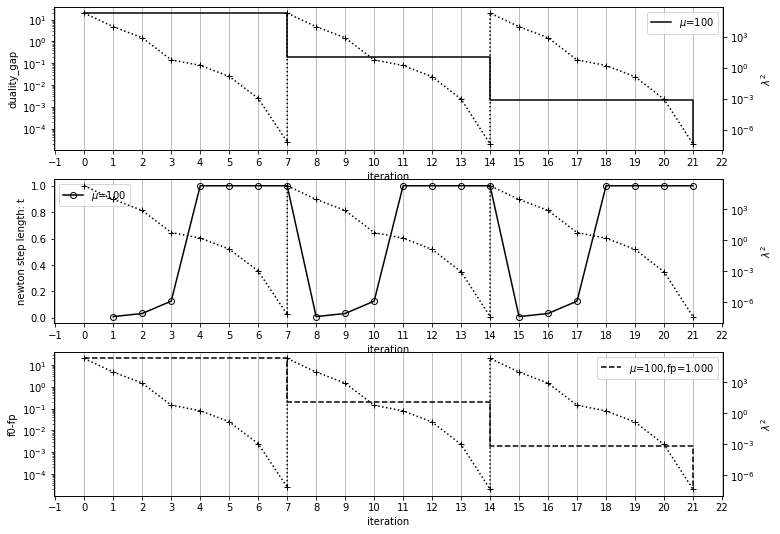

In [83]:
if __name__ == "__main__":
    plot_figure_convergence(n=20, p=20, p_asterisk=1, mu_s=[100], seed=2)


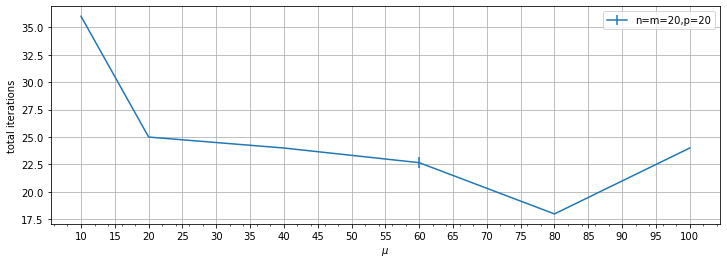

In [84]:
if __name__ == "__main__":
    plot_figure_Newton_iteration_vs_mu(n=20, p=20, p_asterisk=1,
                                       mus=[10, 20, 40, 60, 80, 100], 
                                       n_dial=3)